# Profile plots

Plots that need only the small `_profiles.nc` files (`plots/fetch_profiles.sh` copies them from the cluster). Surface, 3D and checkpoint plots are in `plots.ipynb`.

Functions in `plotter.jl` (docstrings there: `?plot_time_height`). Edits to `plotter.jl` take effect without restarting, through Revise.

In [11]:
# plots/ is the folder with plotter.jl: look from where the kernel started, then at the usual checkouts (hpc, Mac)
plotsdir = first(filter( d -> isfile(joinpath(d, "plotter.jl")) ,
            ( pwd(), joinpath(pwd(), "plots"), dirname(pwd()),
              "/ceoas/deszoeks/projects/monsoon-breeze/plots",
              expanduser("~/projects/monsoon-breeze/plots") )   ))
cd(plotsdir)
using Pkg; Pkg.activate(plotsdir)
using Revise
includet(joinpath(plotsdir, "plotter.jl"))

rundir = joinpath(dirname(plotsdir), "run", "ekamsat-p3-ctl0")

  Activating project at `/ceoas/deszoeks/projects/monsoon-breeze/plots`


"/ceoas/deszoeks/projects/monsoon-breeze/run/ekamsat-p3-ctl0"

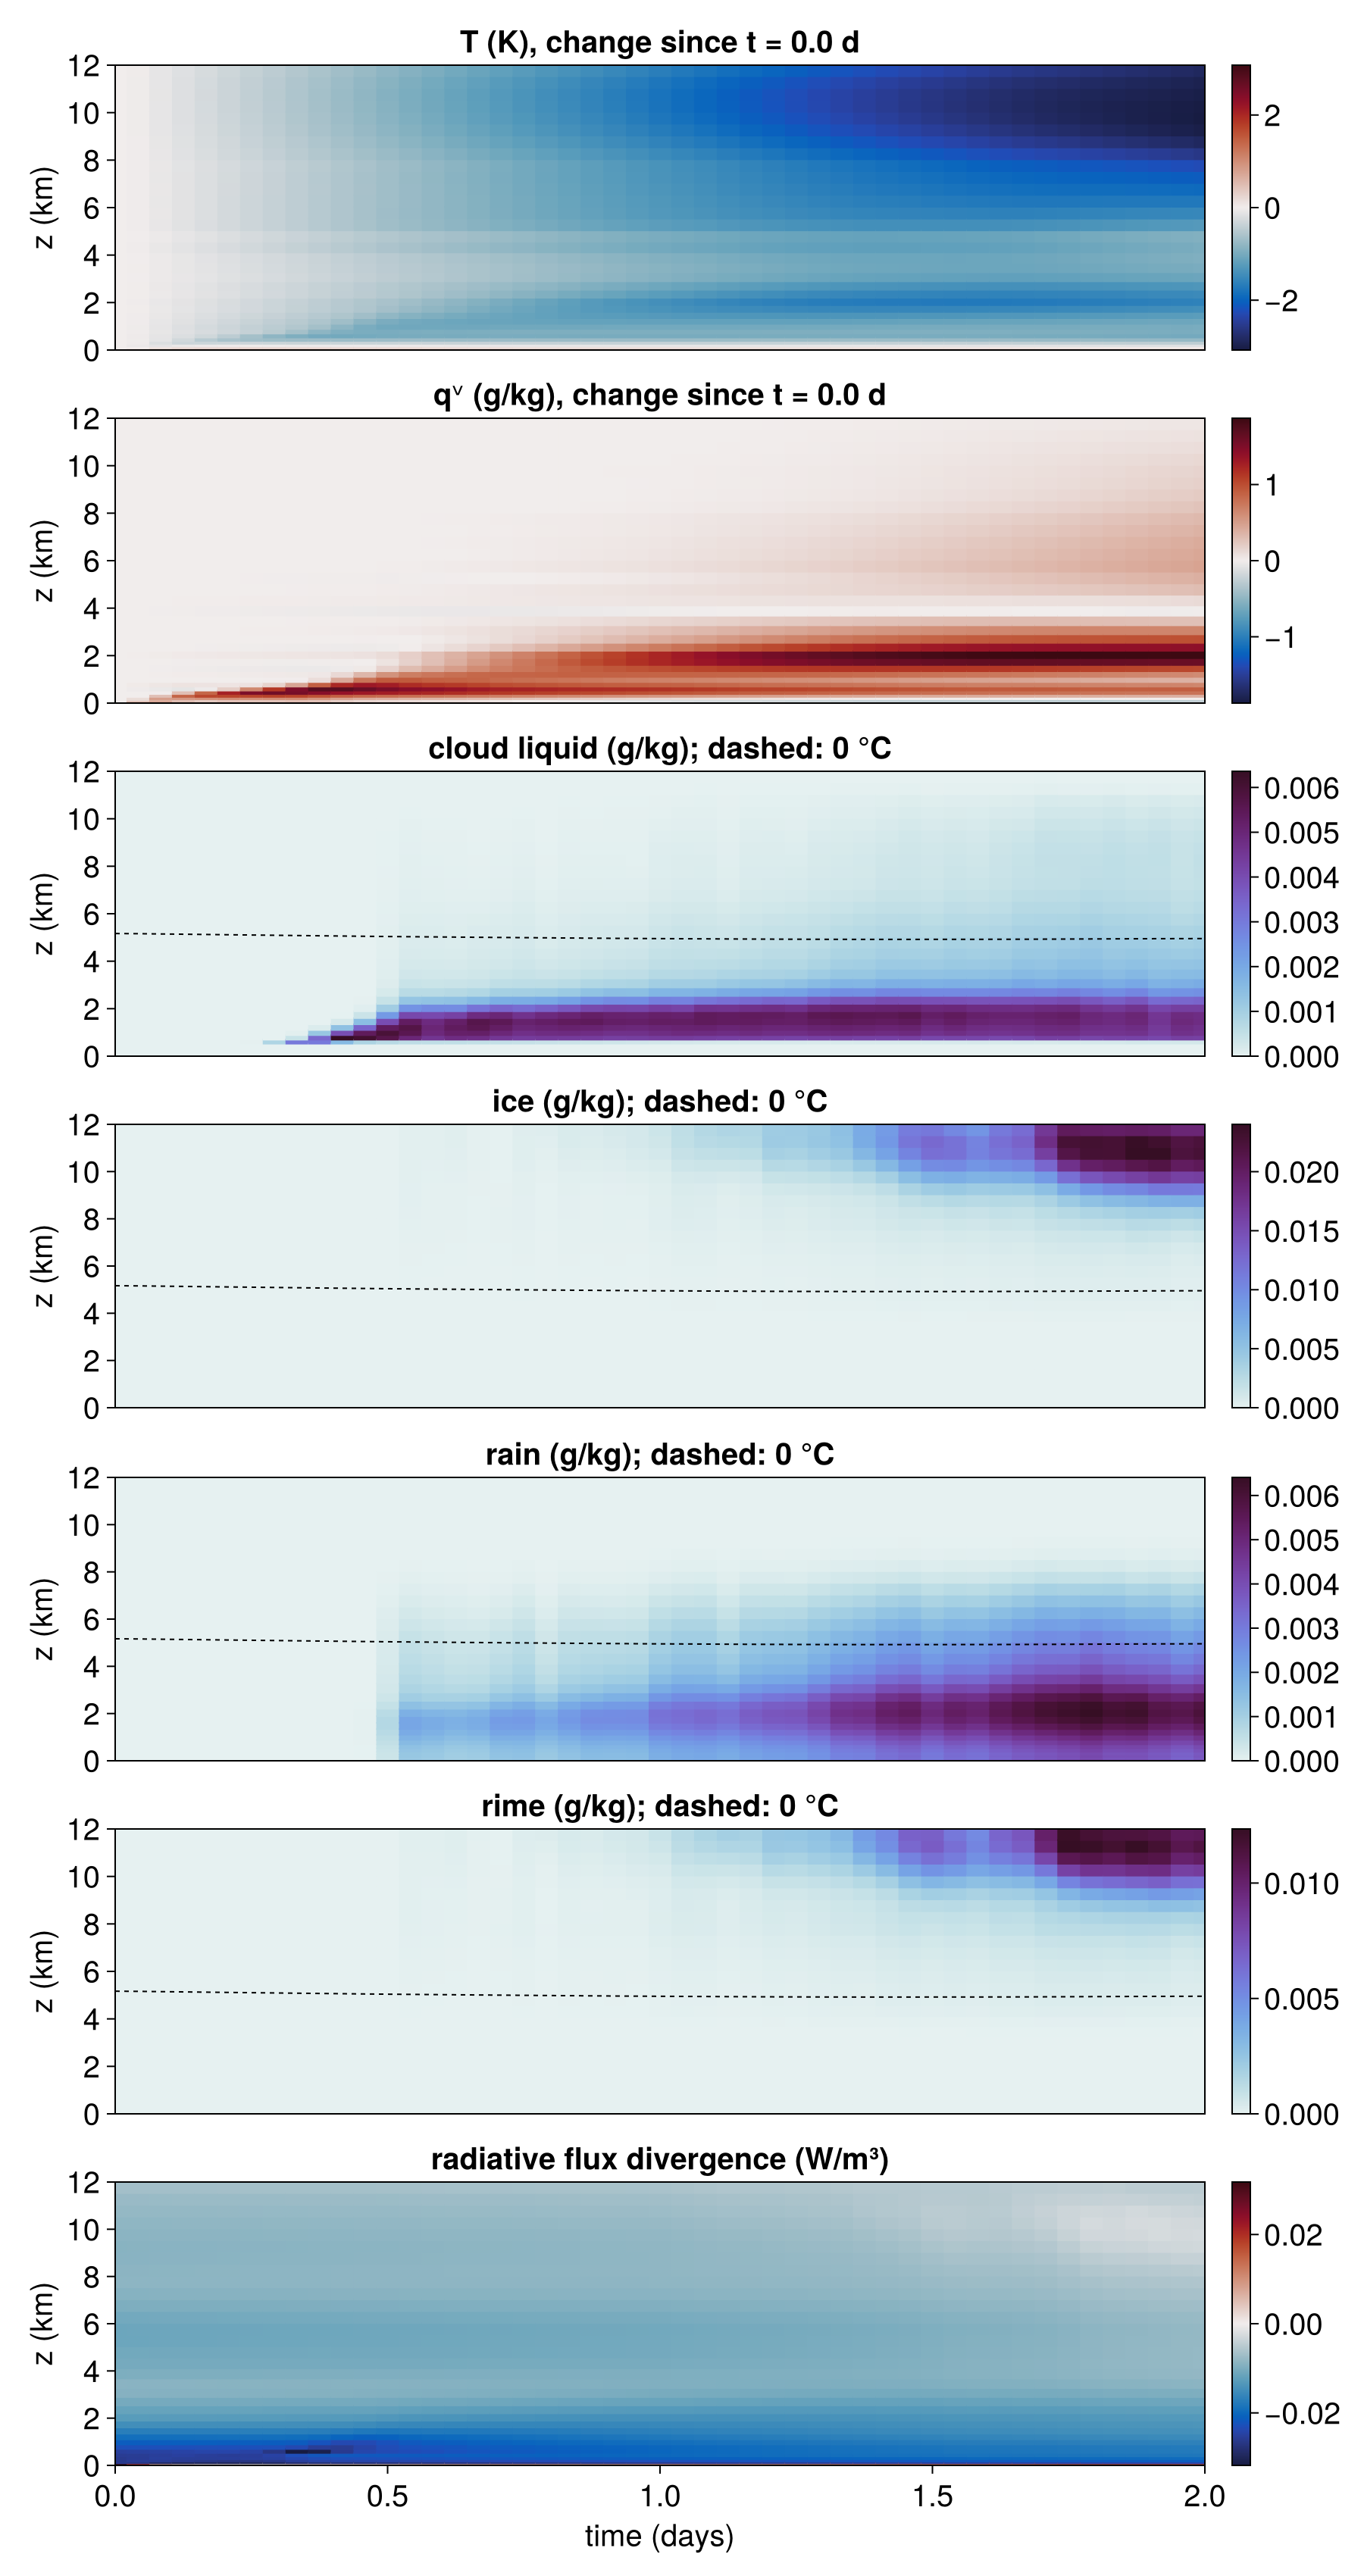

In [12]:
fig = plot_time_height(rundir; zmax = 12_000)

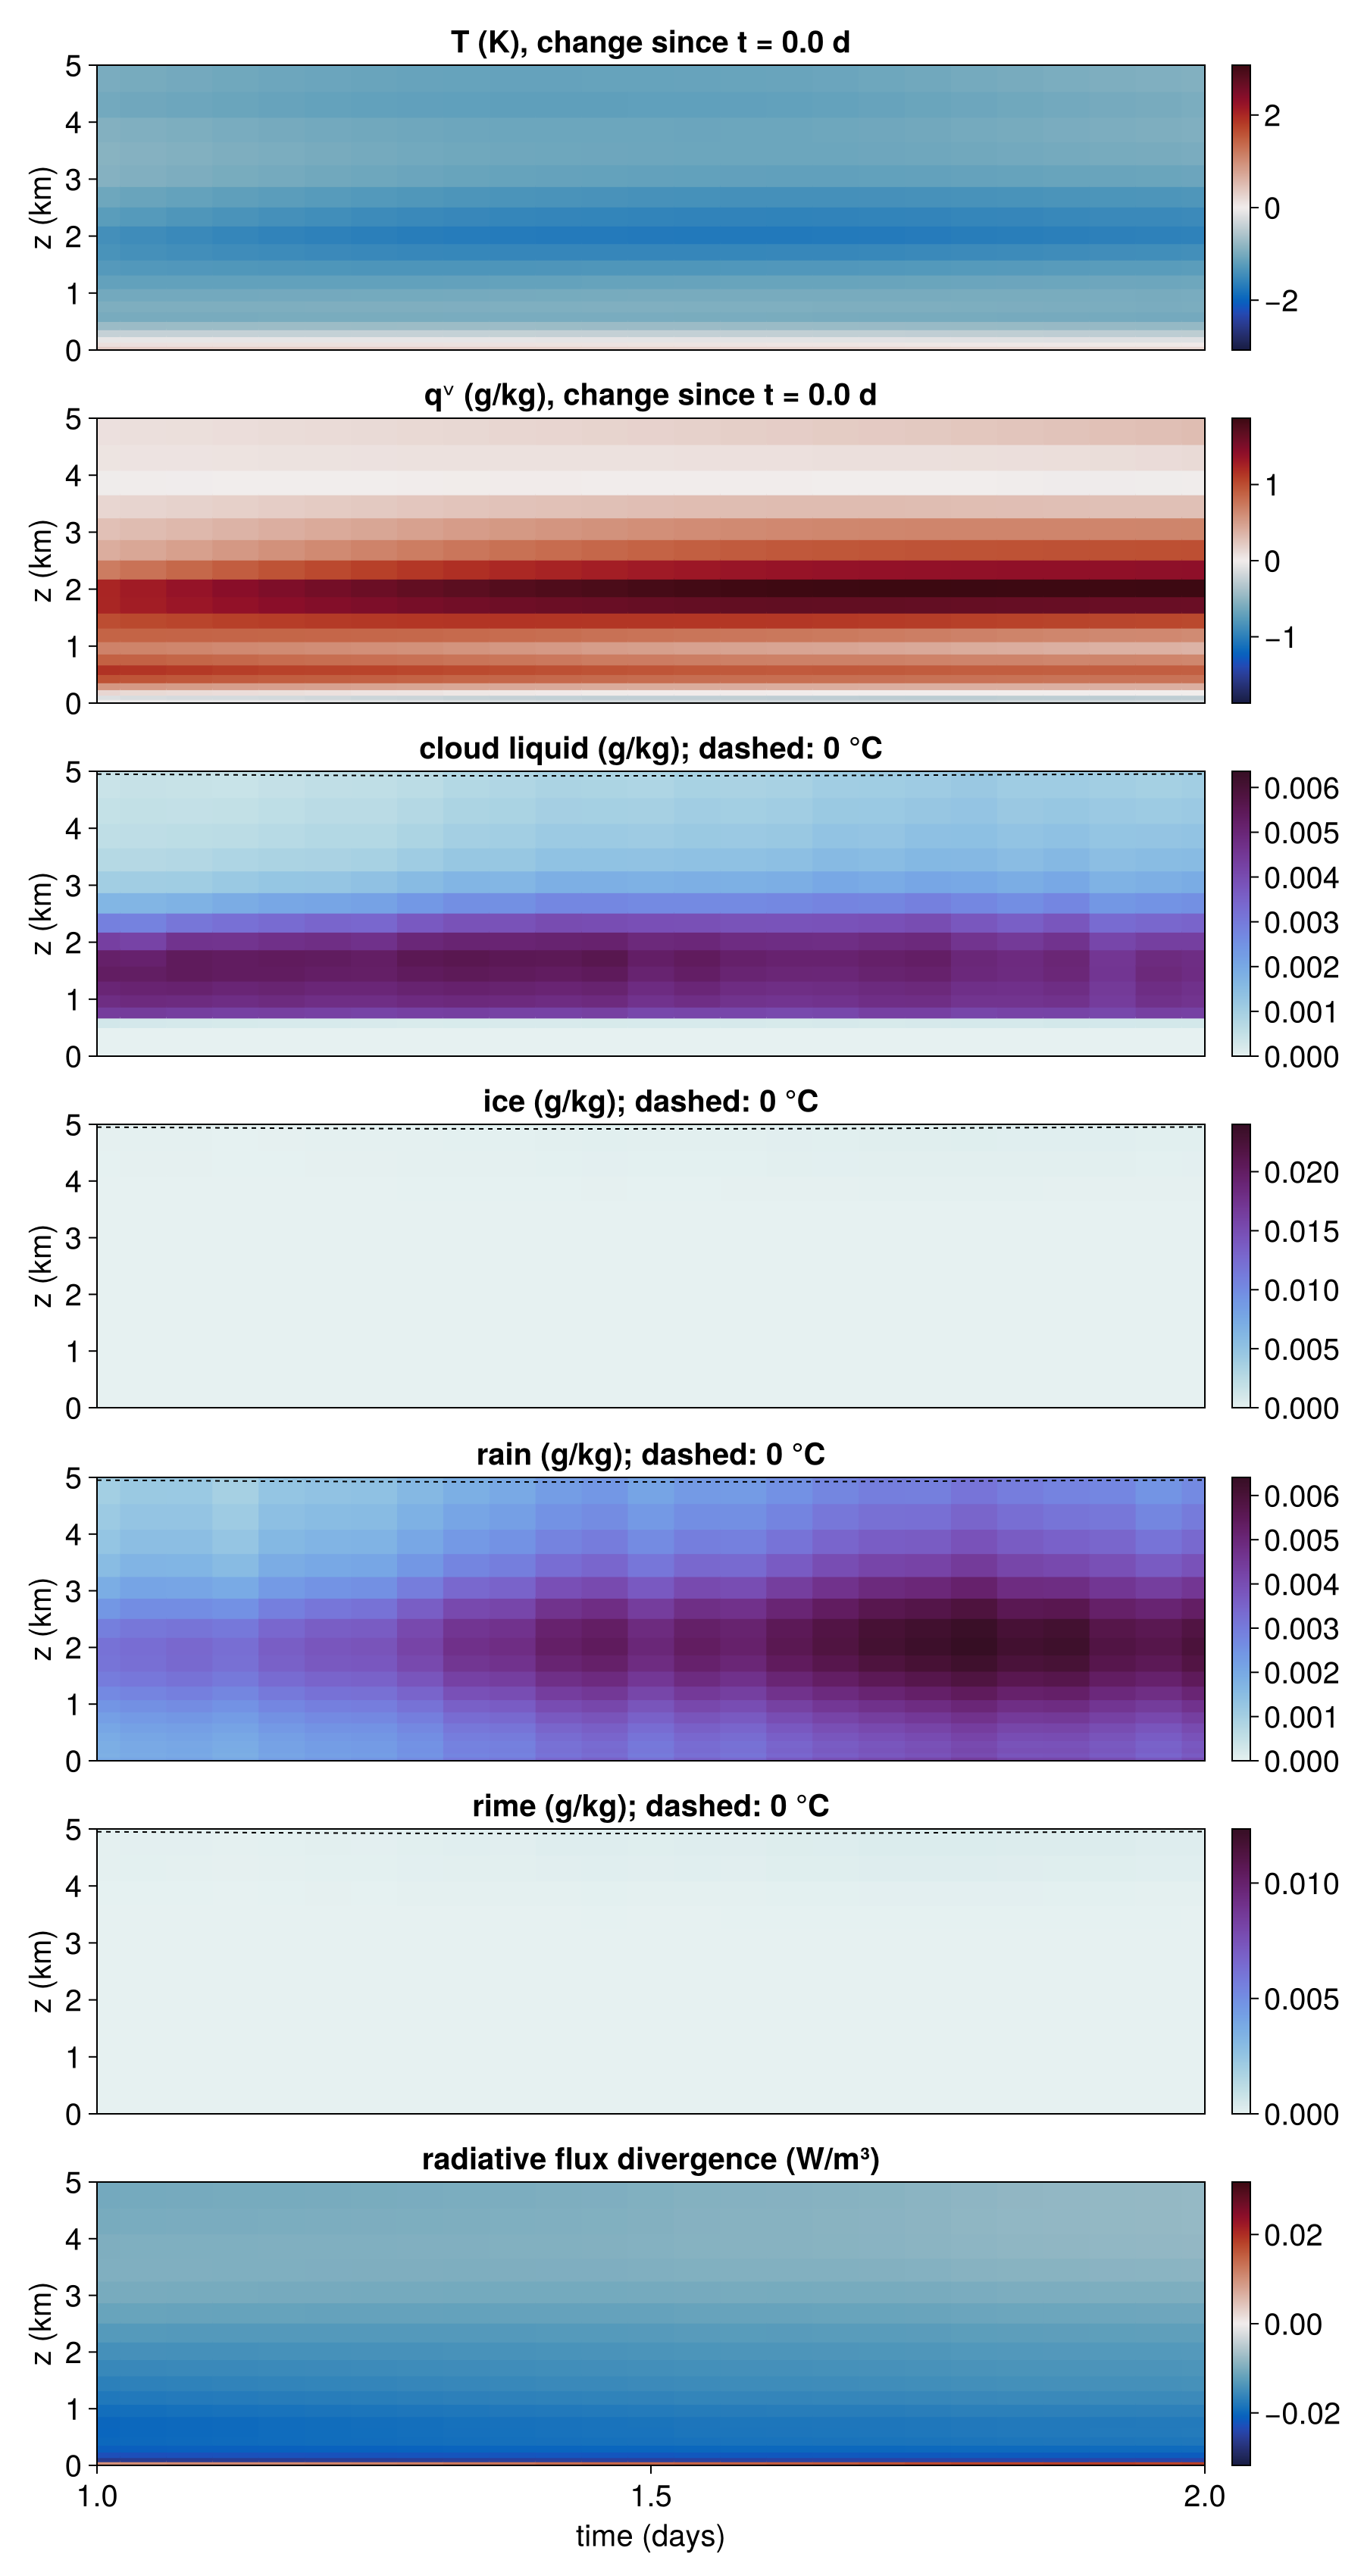

In [13]:
# Zoom: get a plotted axis (panel 2, qᵛ) and set its limits, then show the figure again.
# Time–height panels share the time axis, so xlims! zooms them all.
axs = plot_axes(fig)
for ax in axs
    xlims!(ax, 1, 2)      # days
    ylims!(ax, 0, 5)      # km
end
fig

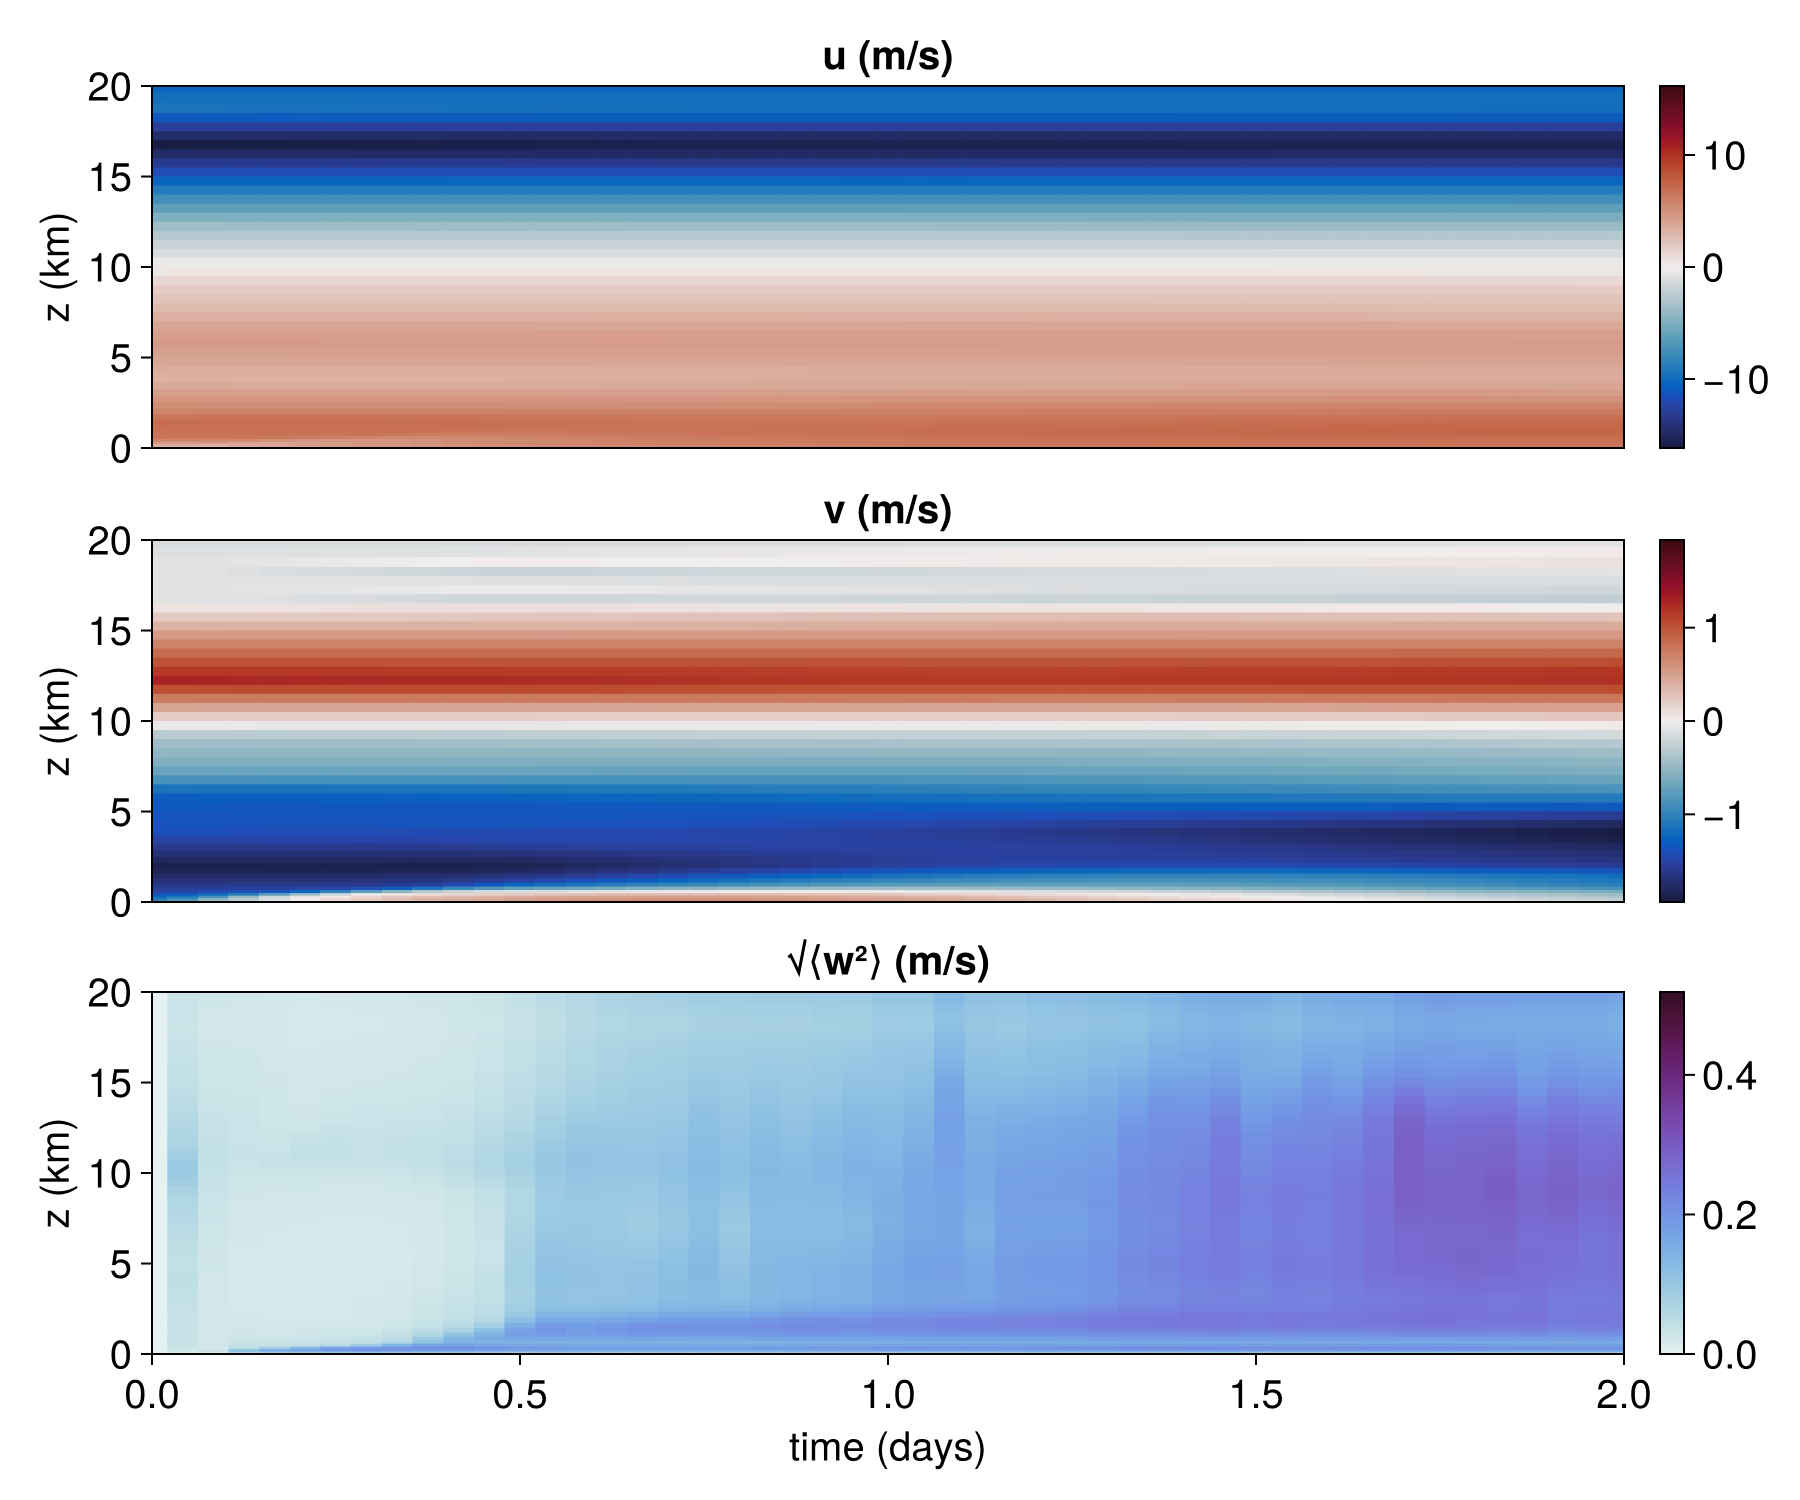

In [14]:
fig_wind = plot_wind_time_height(rundir)

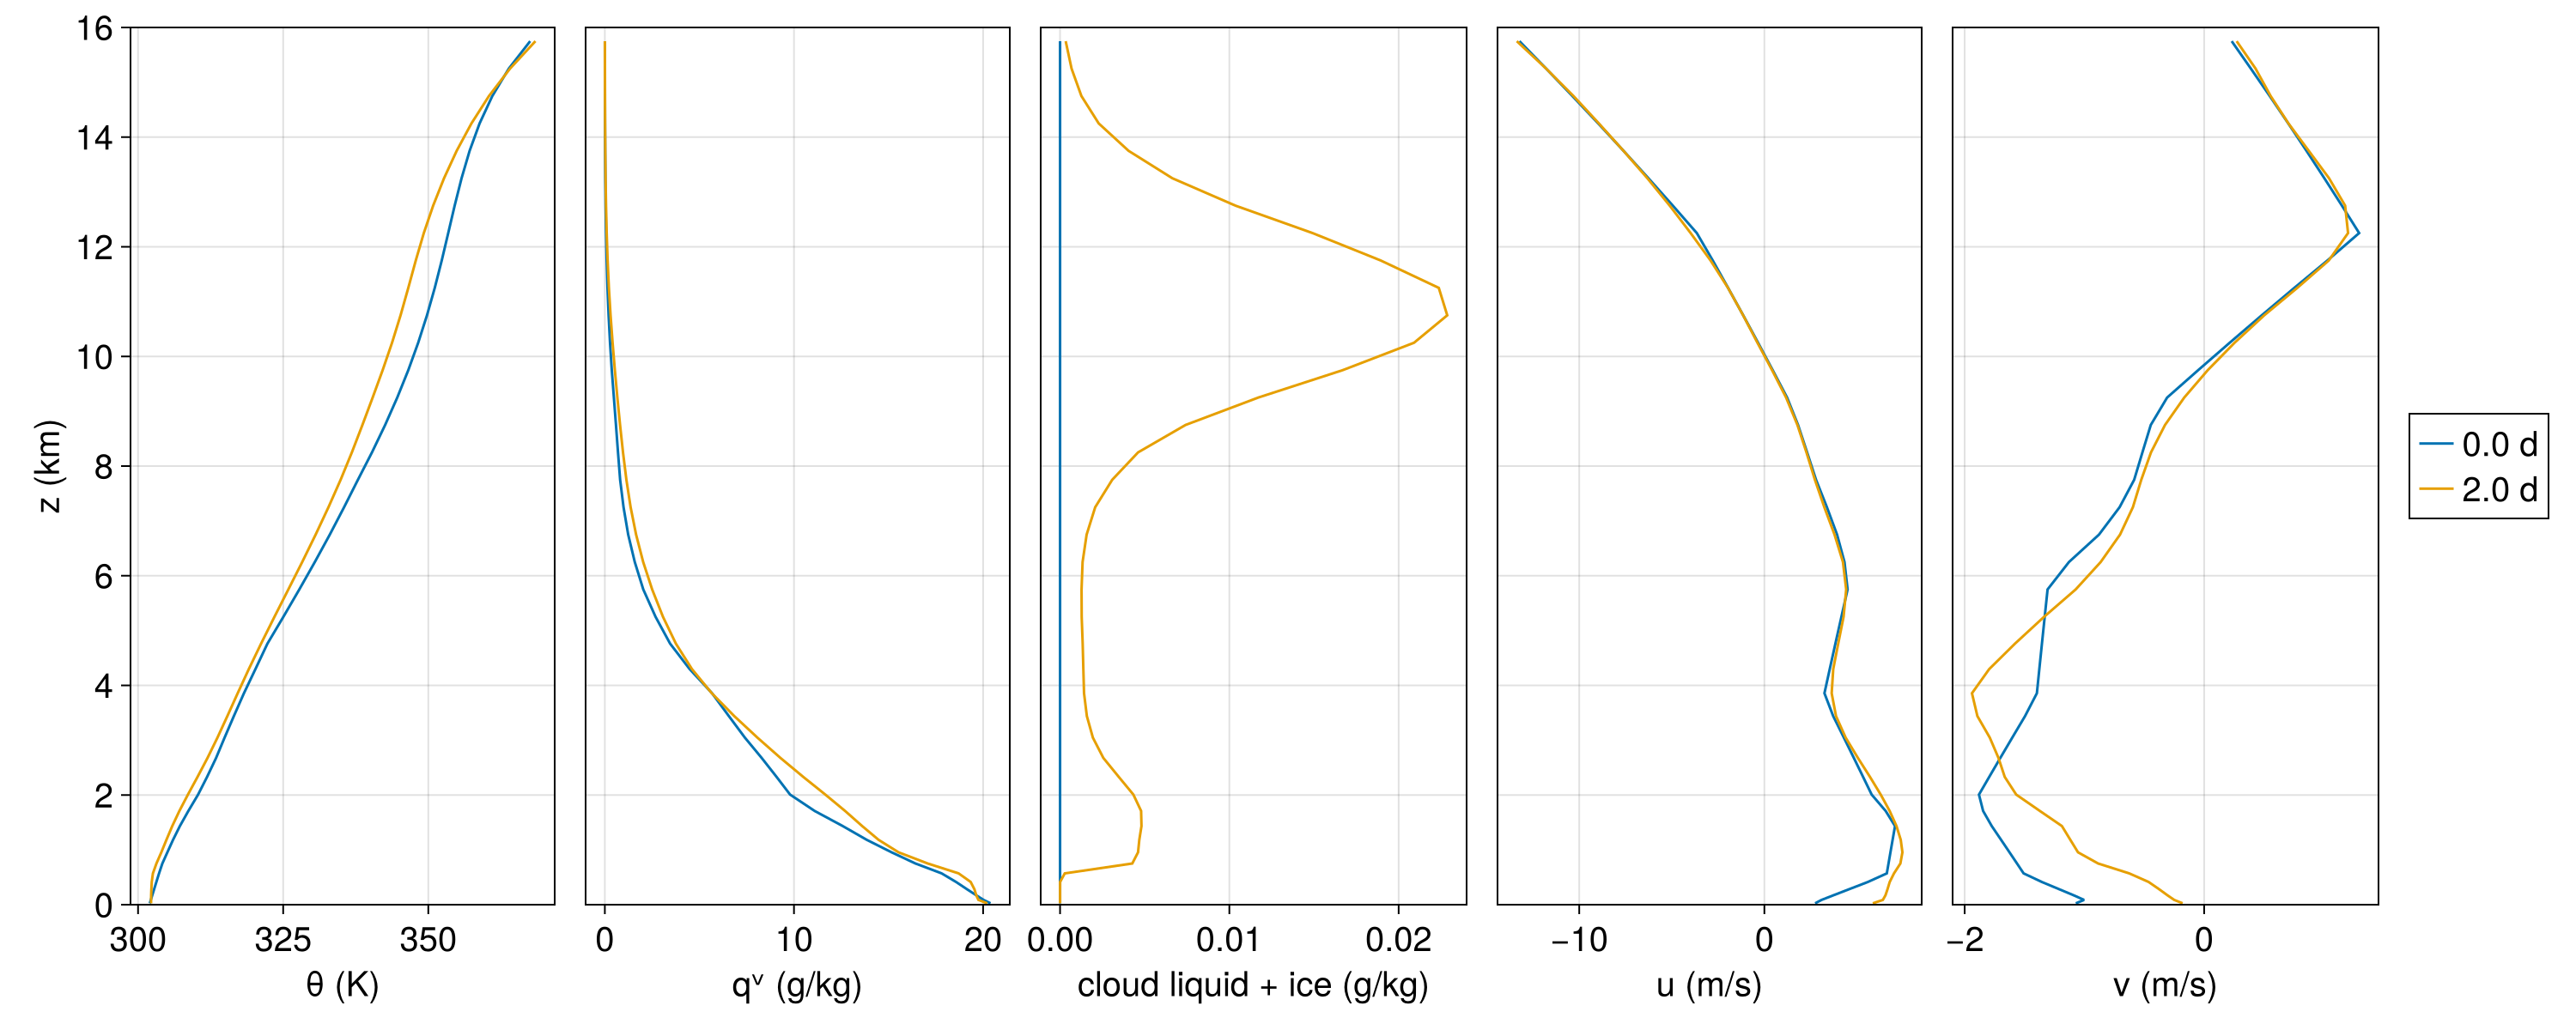

In [15]:
fig_profiles = plot_profiles(rundir; ns = (first, last))

## P3 runs

Fetch the small profile files on the Mac with `plots/fetch_profiles.sh`; on the cluster they are already there. Control extension and the three moistening branches, from the 2-day branch point.

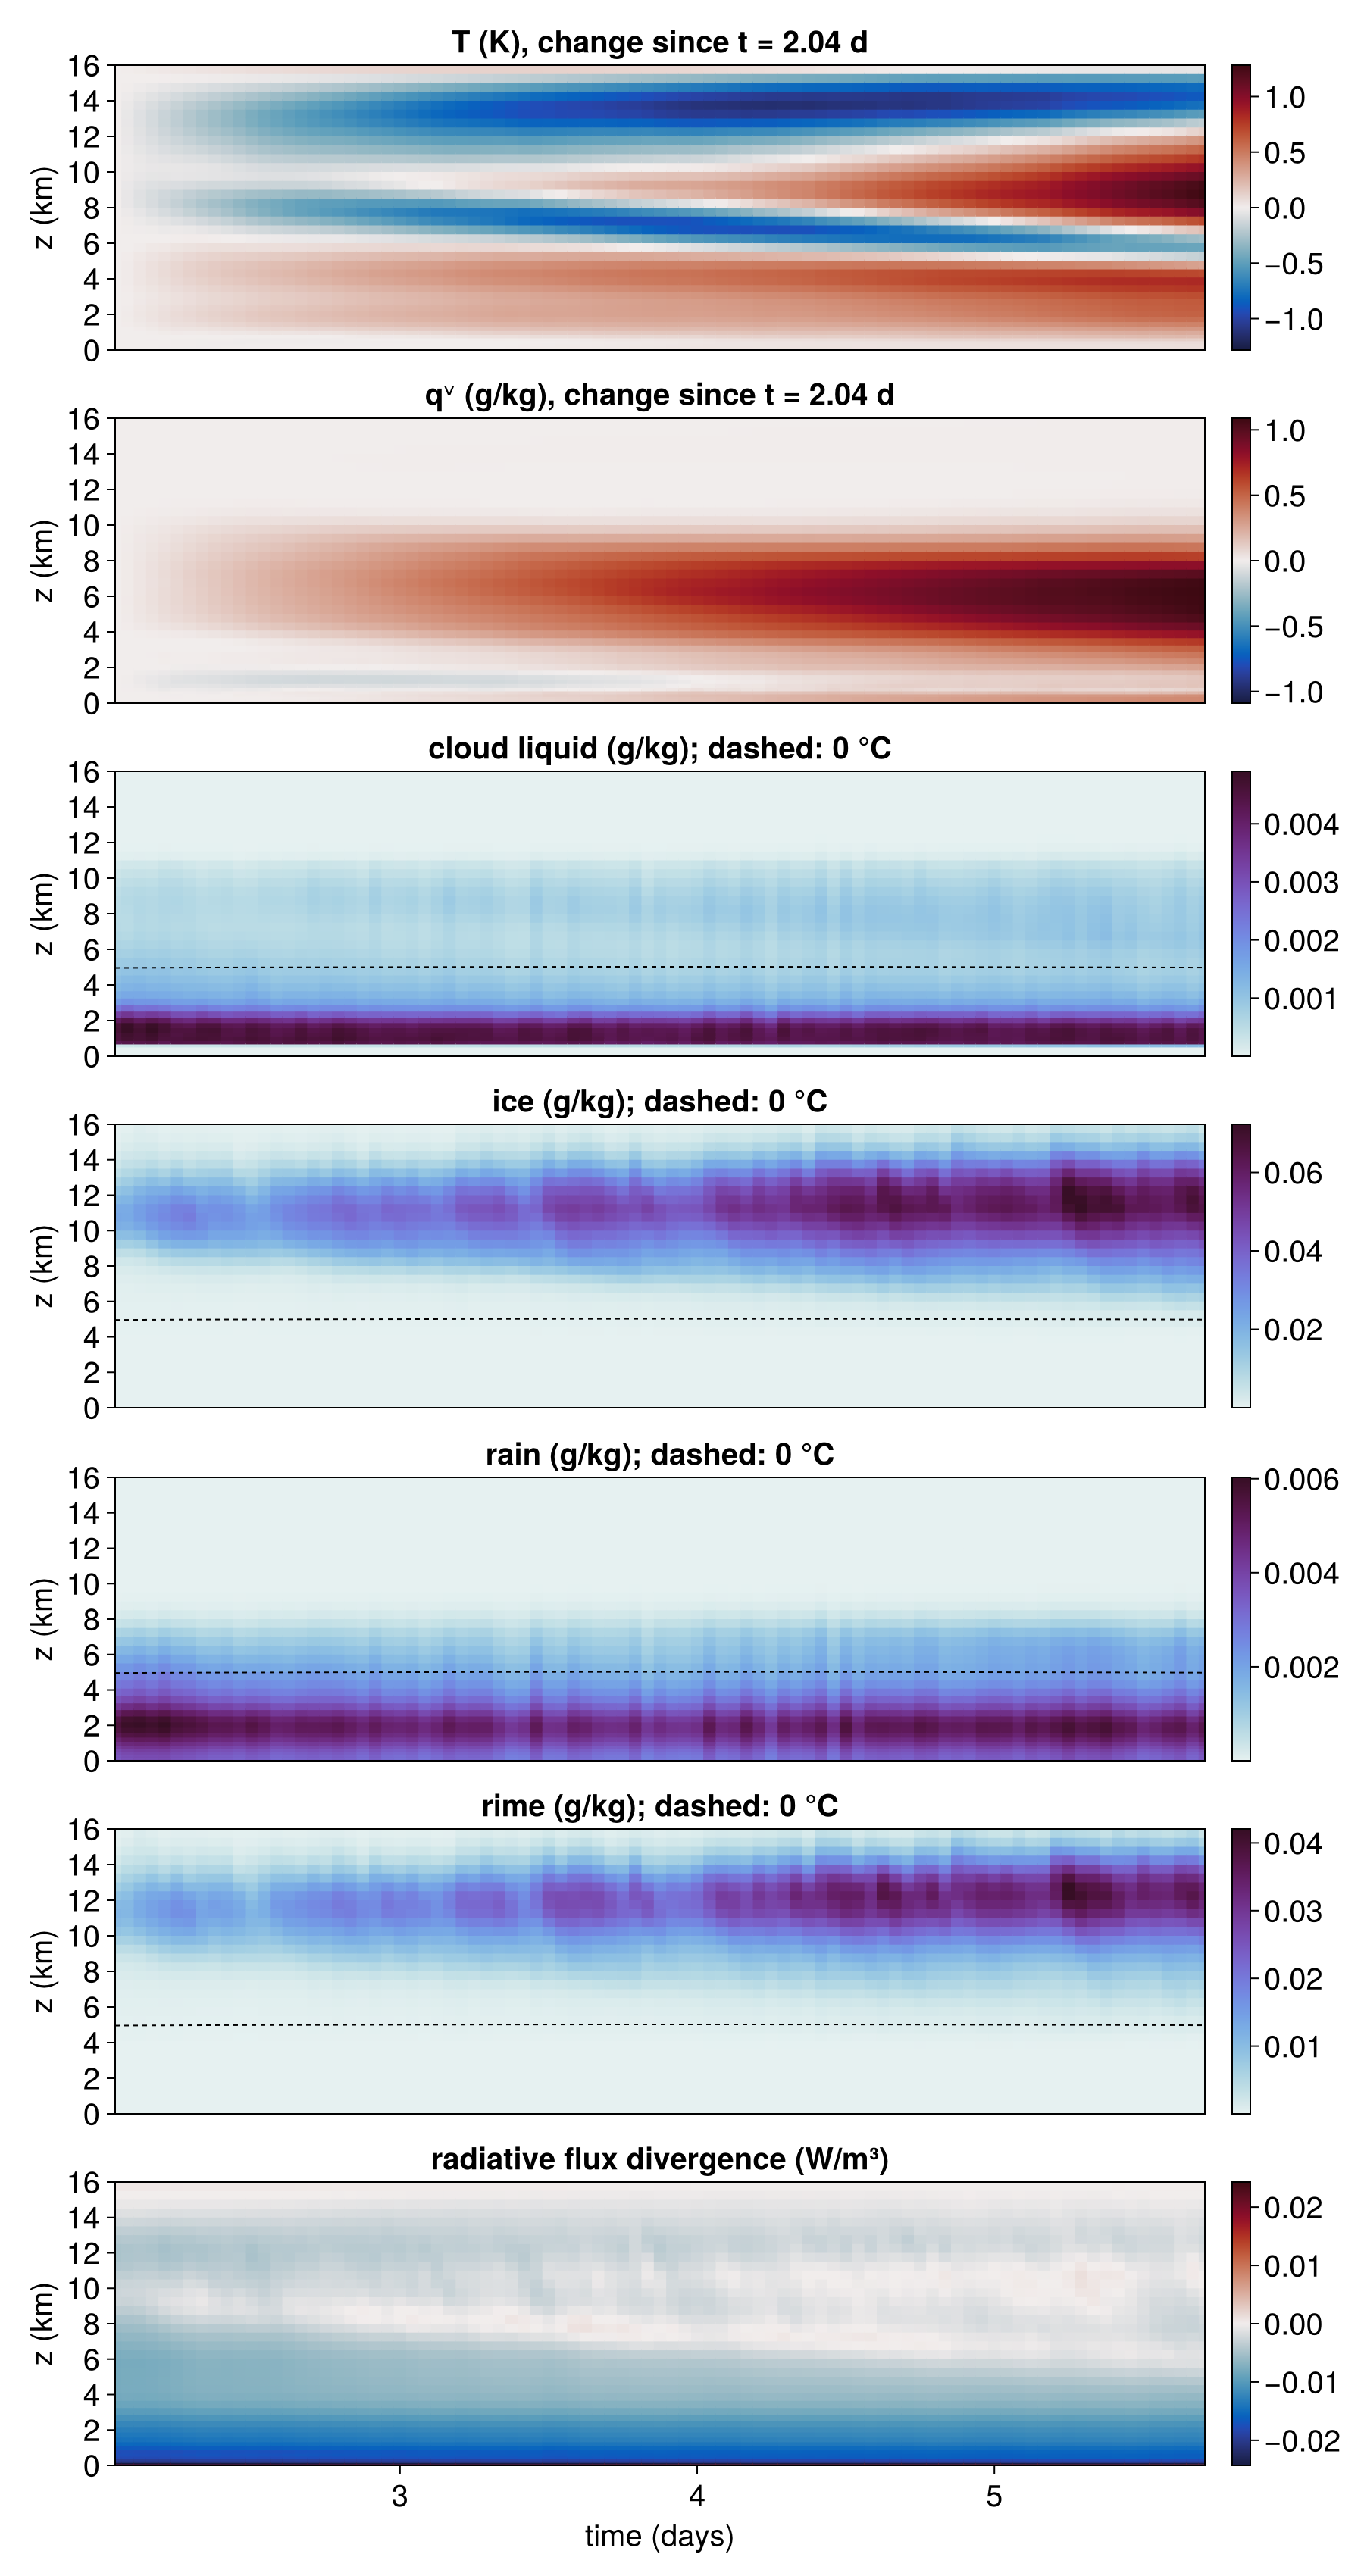

In [16]:
p3runs = ["ctl2", "moisten1000-850", "moisten850-650", "moisten650-440"]
p3dir(r) = joinpath("../run", "ekamsat-p3-$r")
figs_p3 = Dict(r => plot_time_height(p3dir(r); zmax = 16_000) for r in p3runs)
figs_p3["ctl2"]

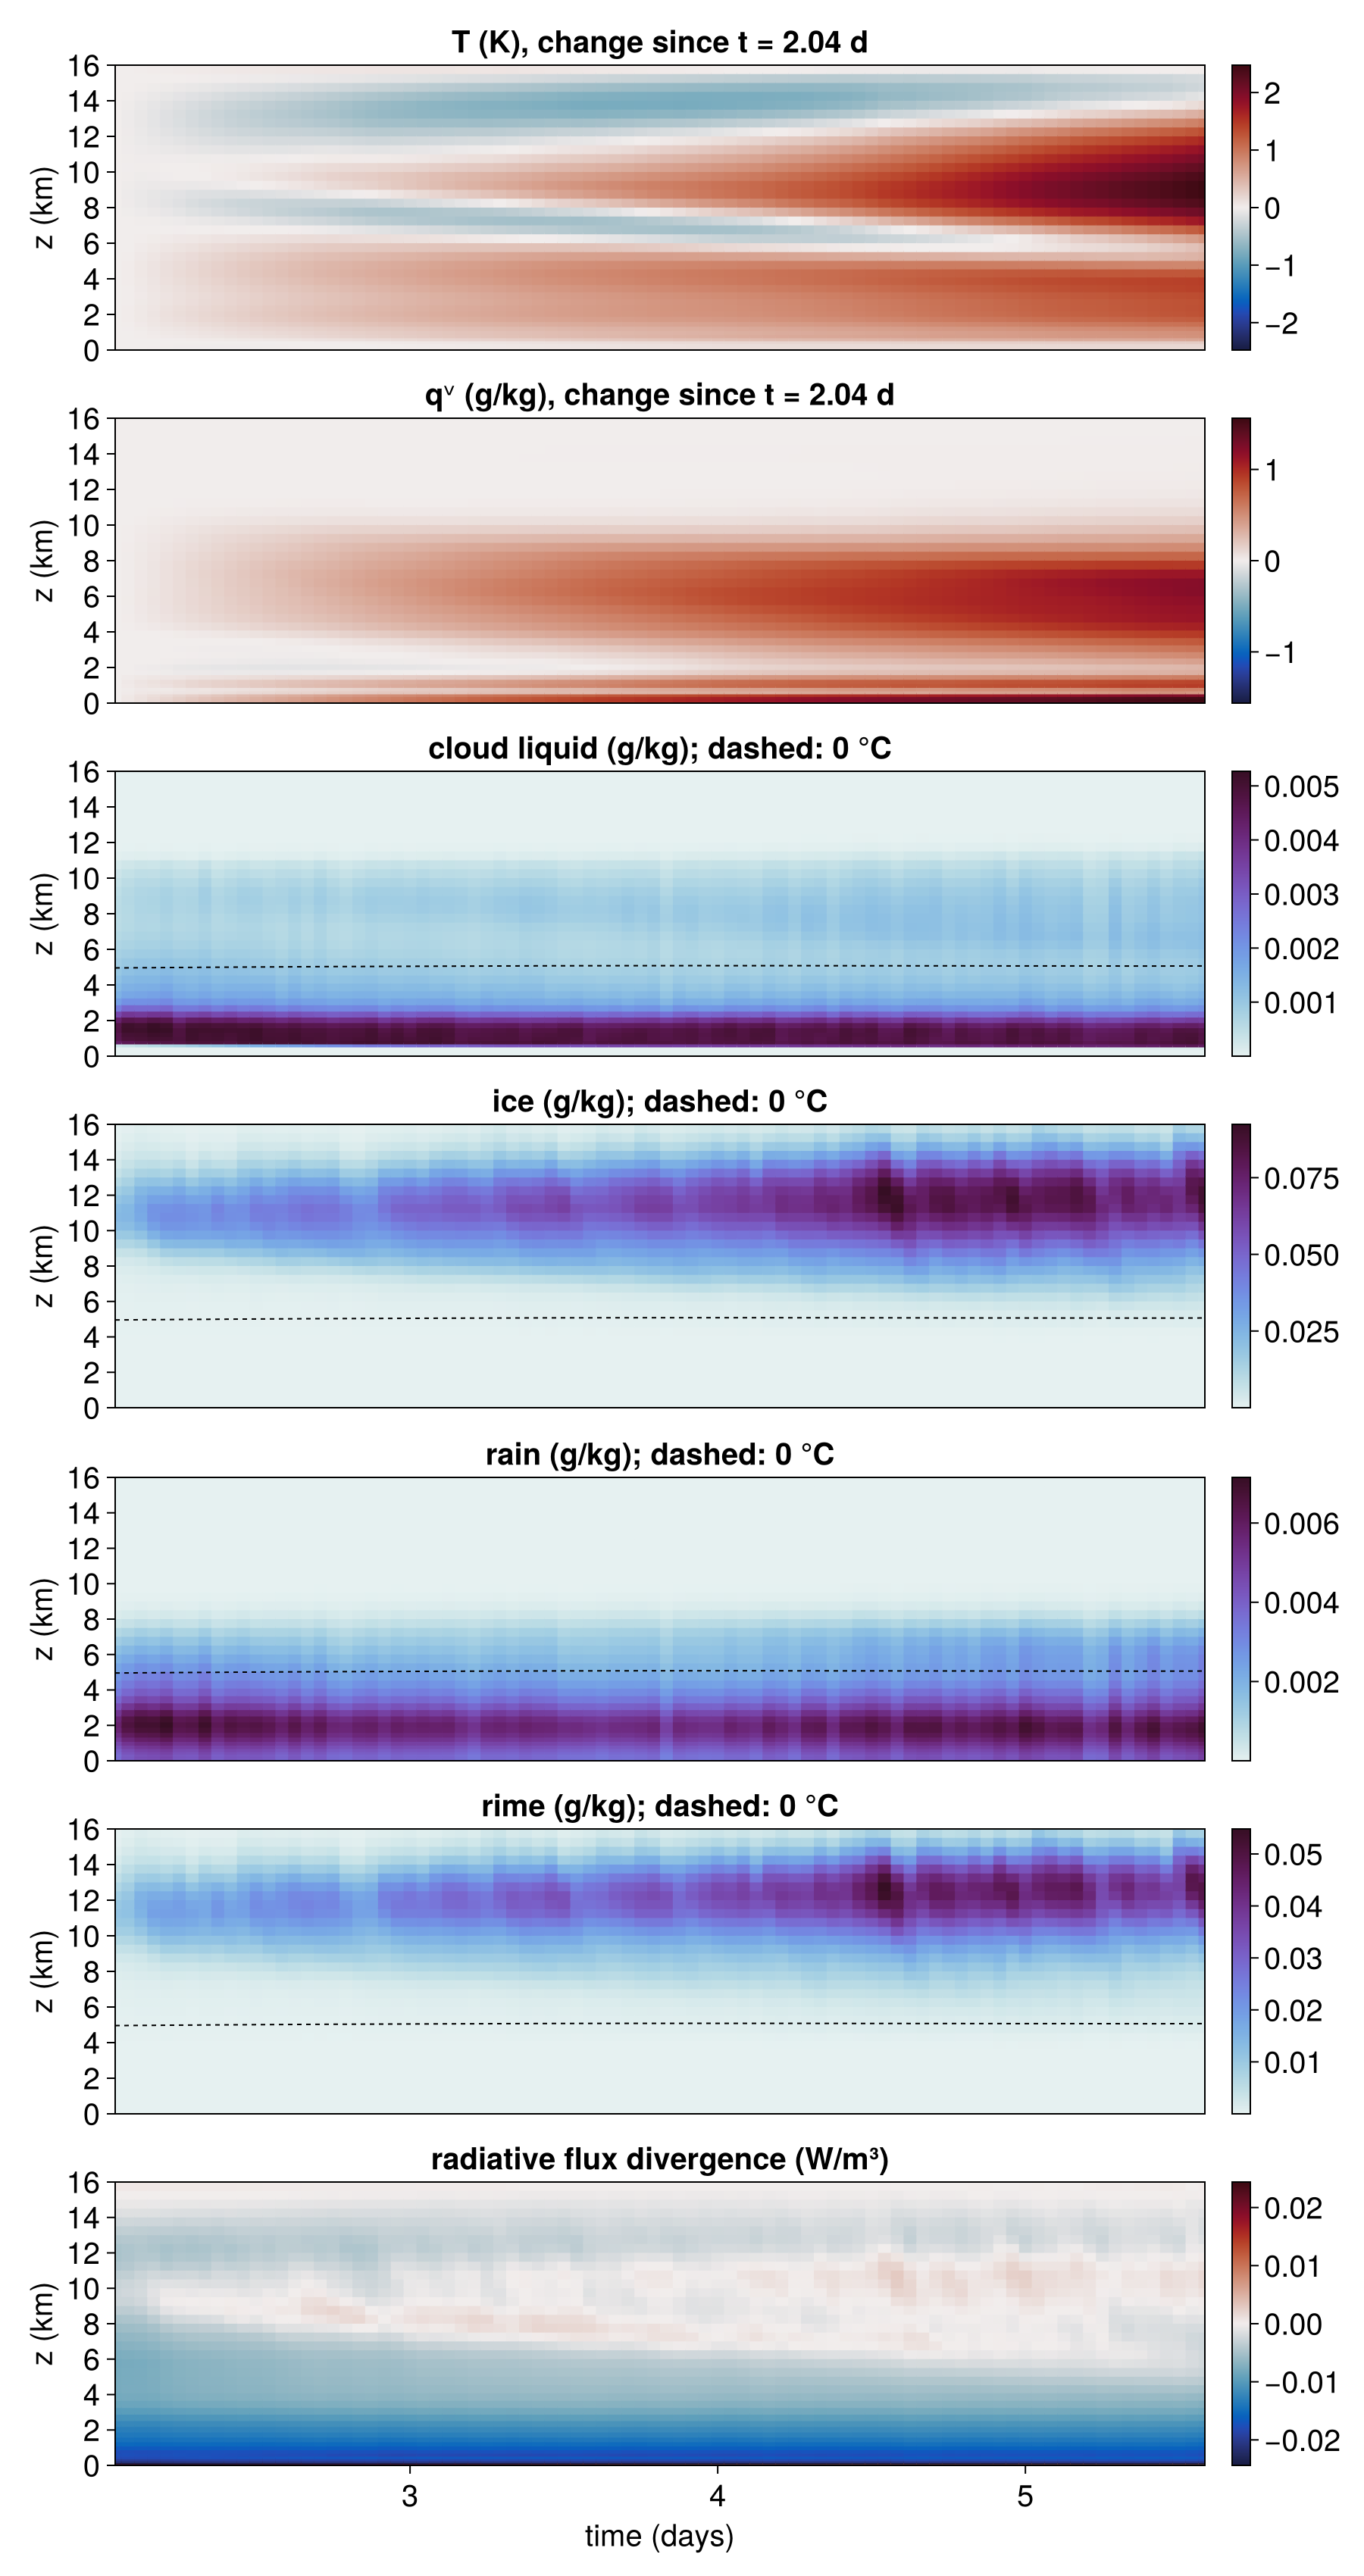

In [17]:
figs_p3["moisten1000-850"]

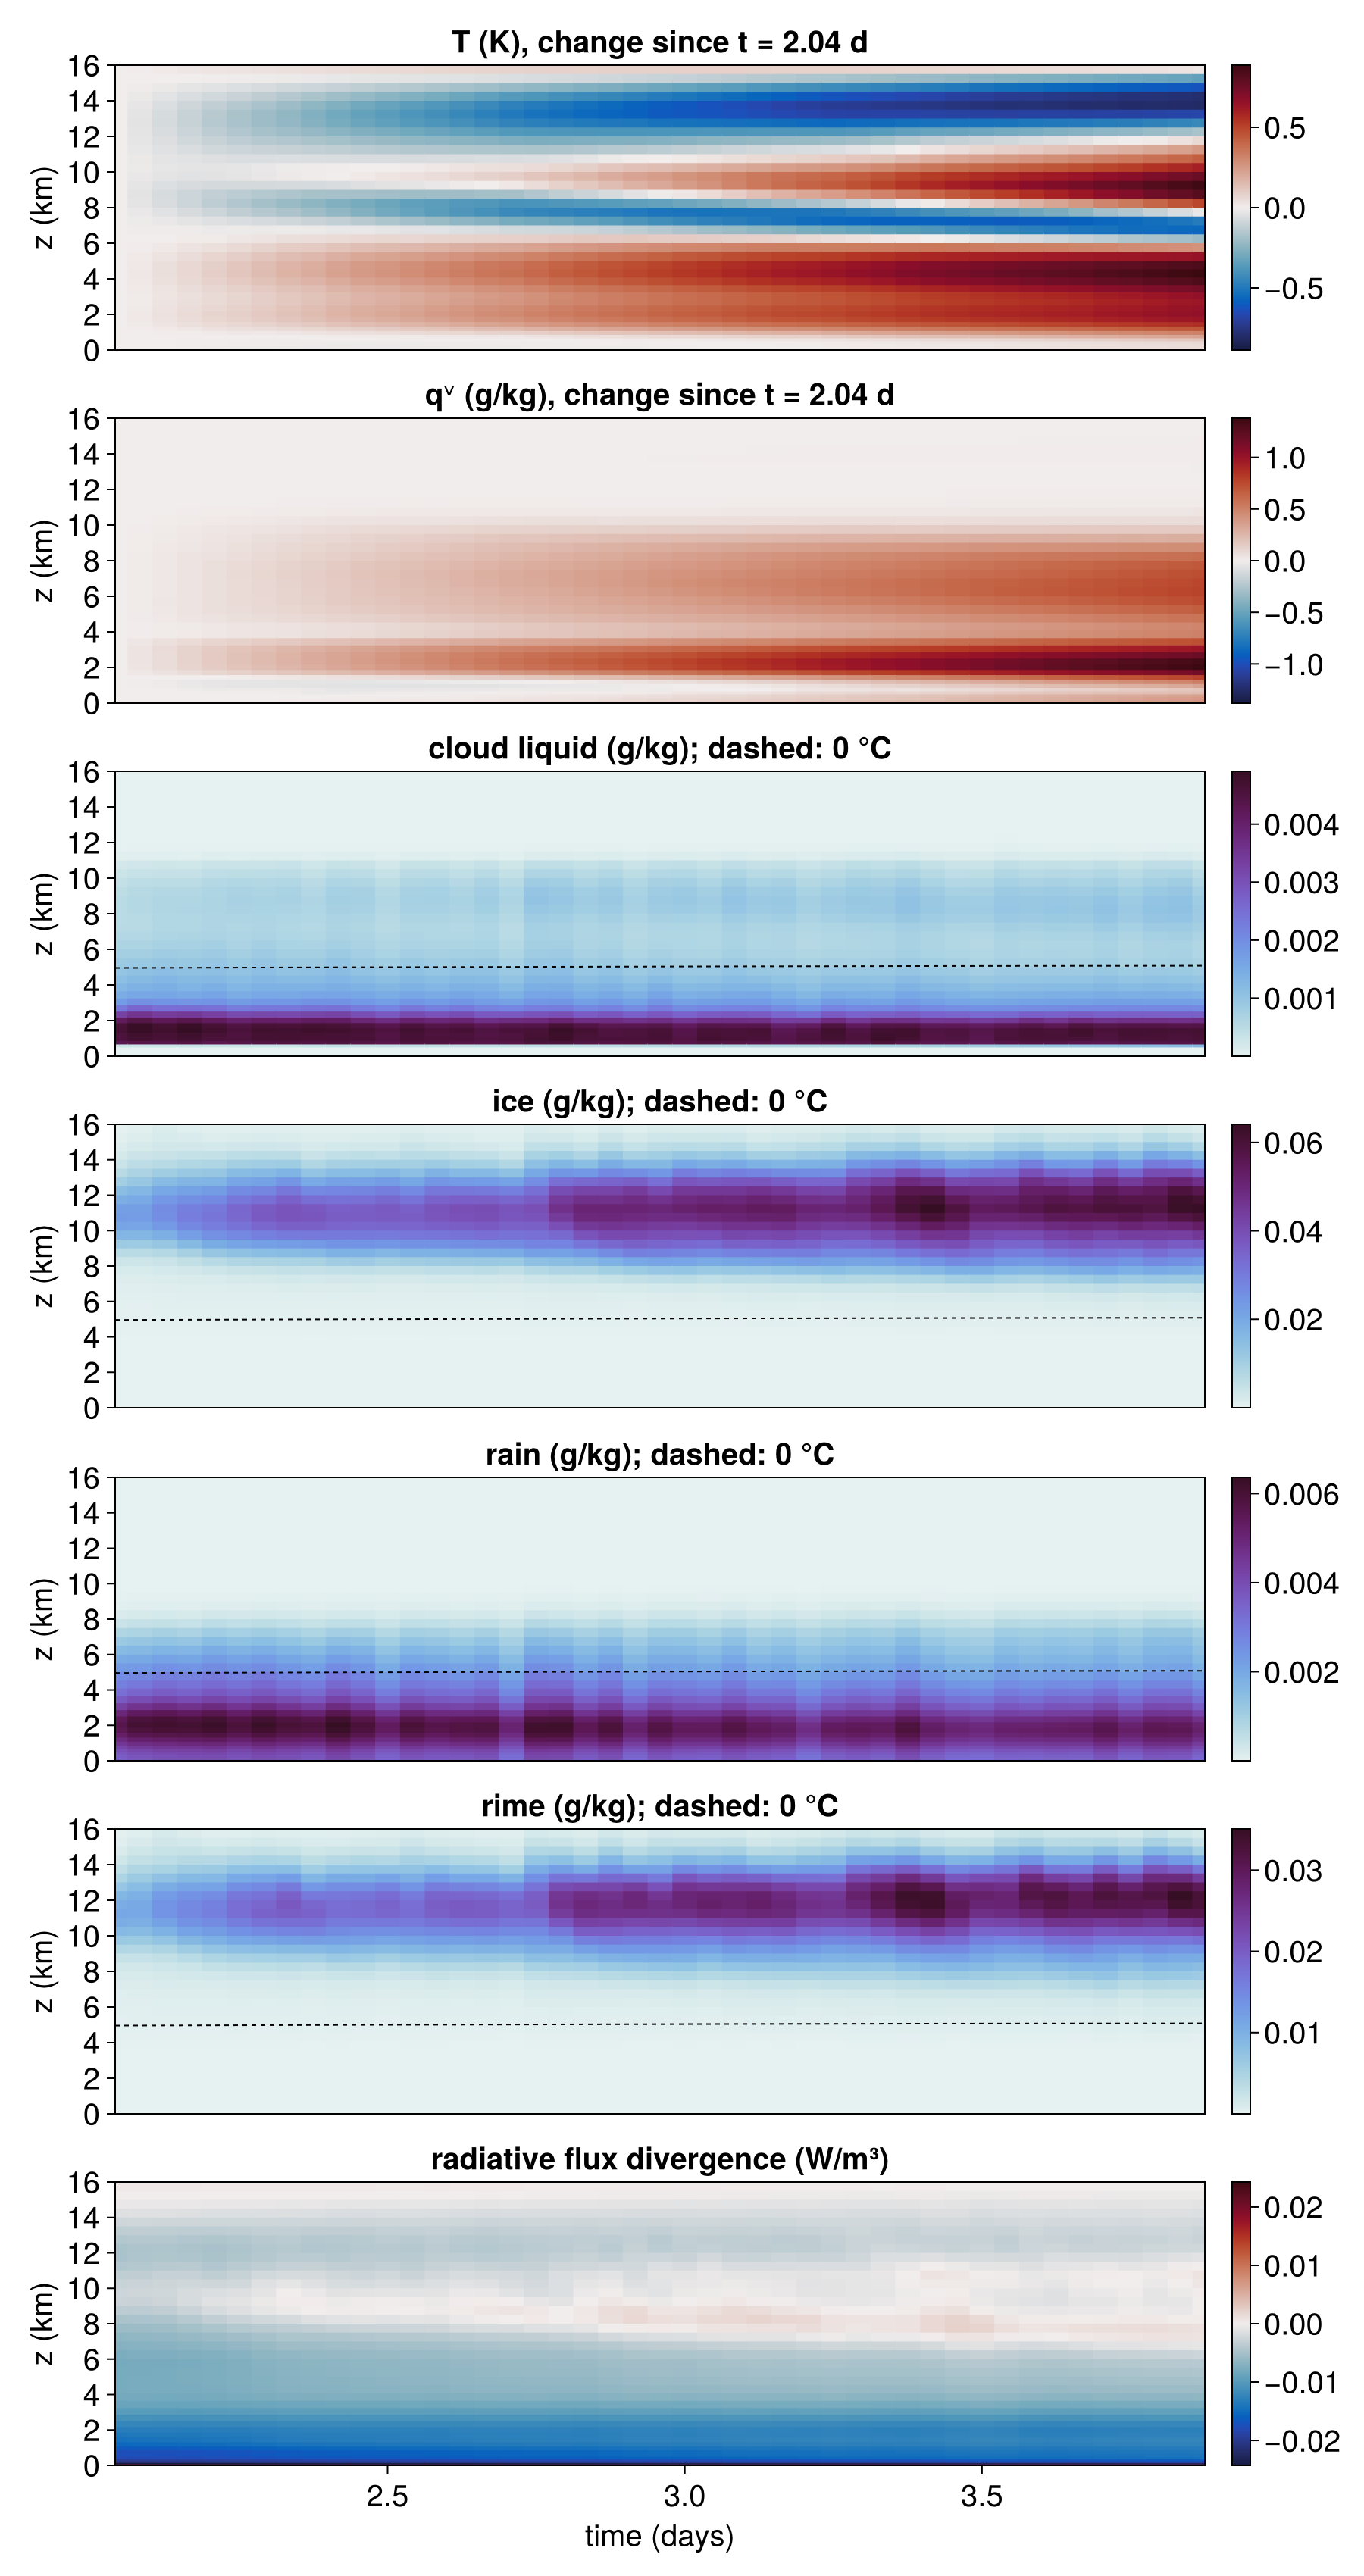

In [18]:
figs_p3["moisten850-650"]

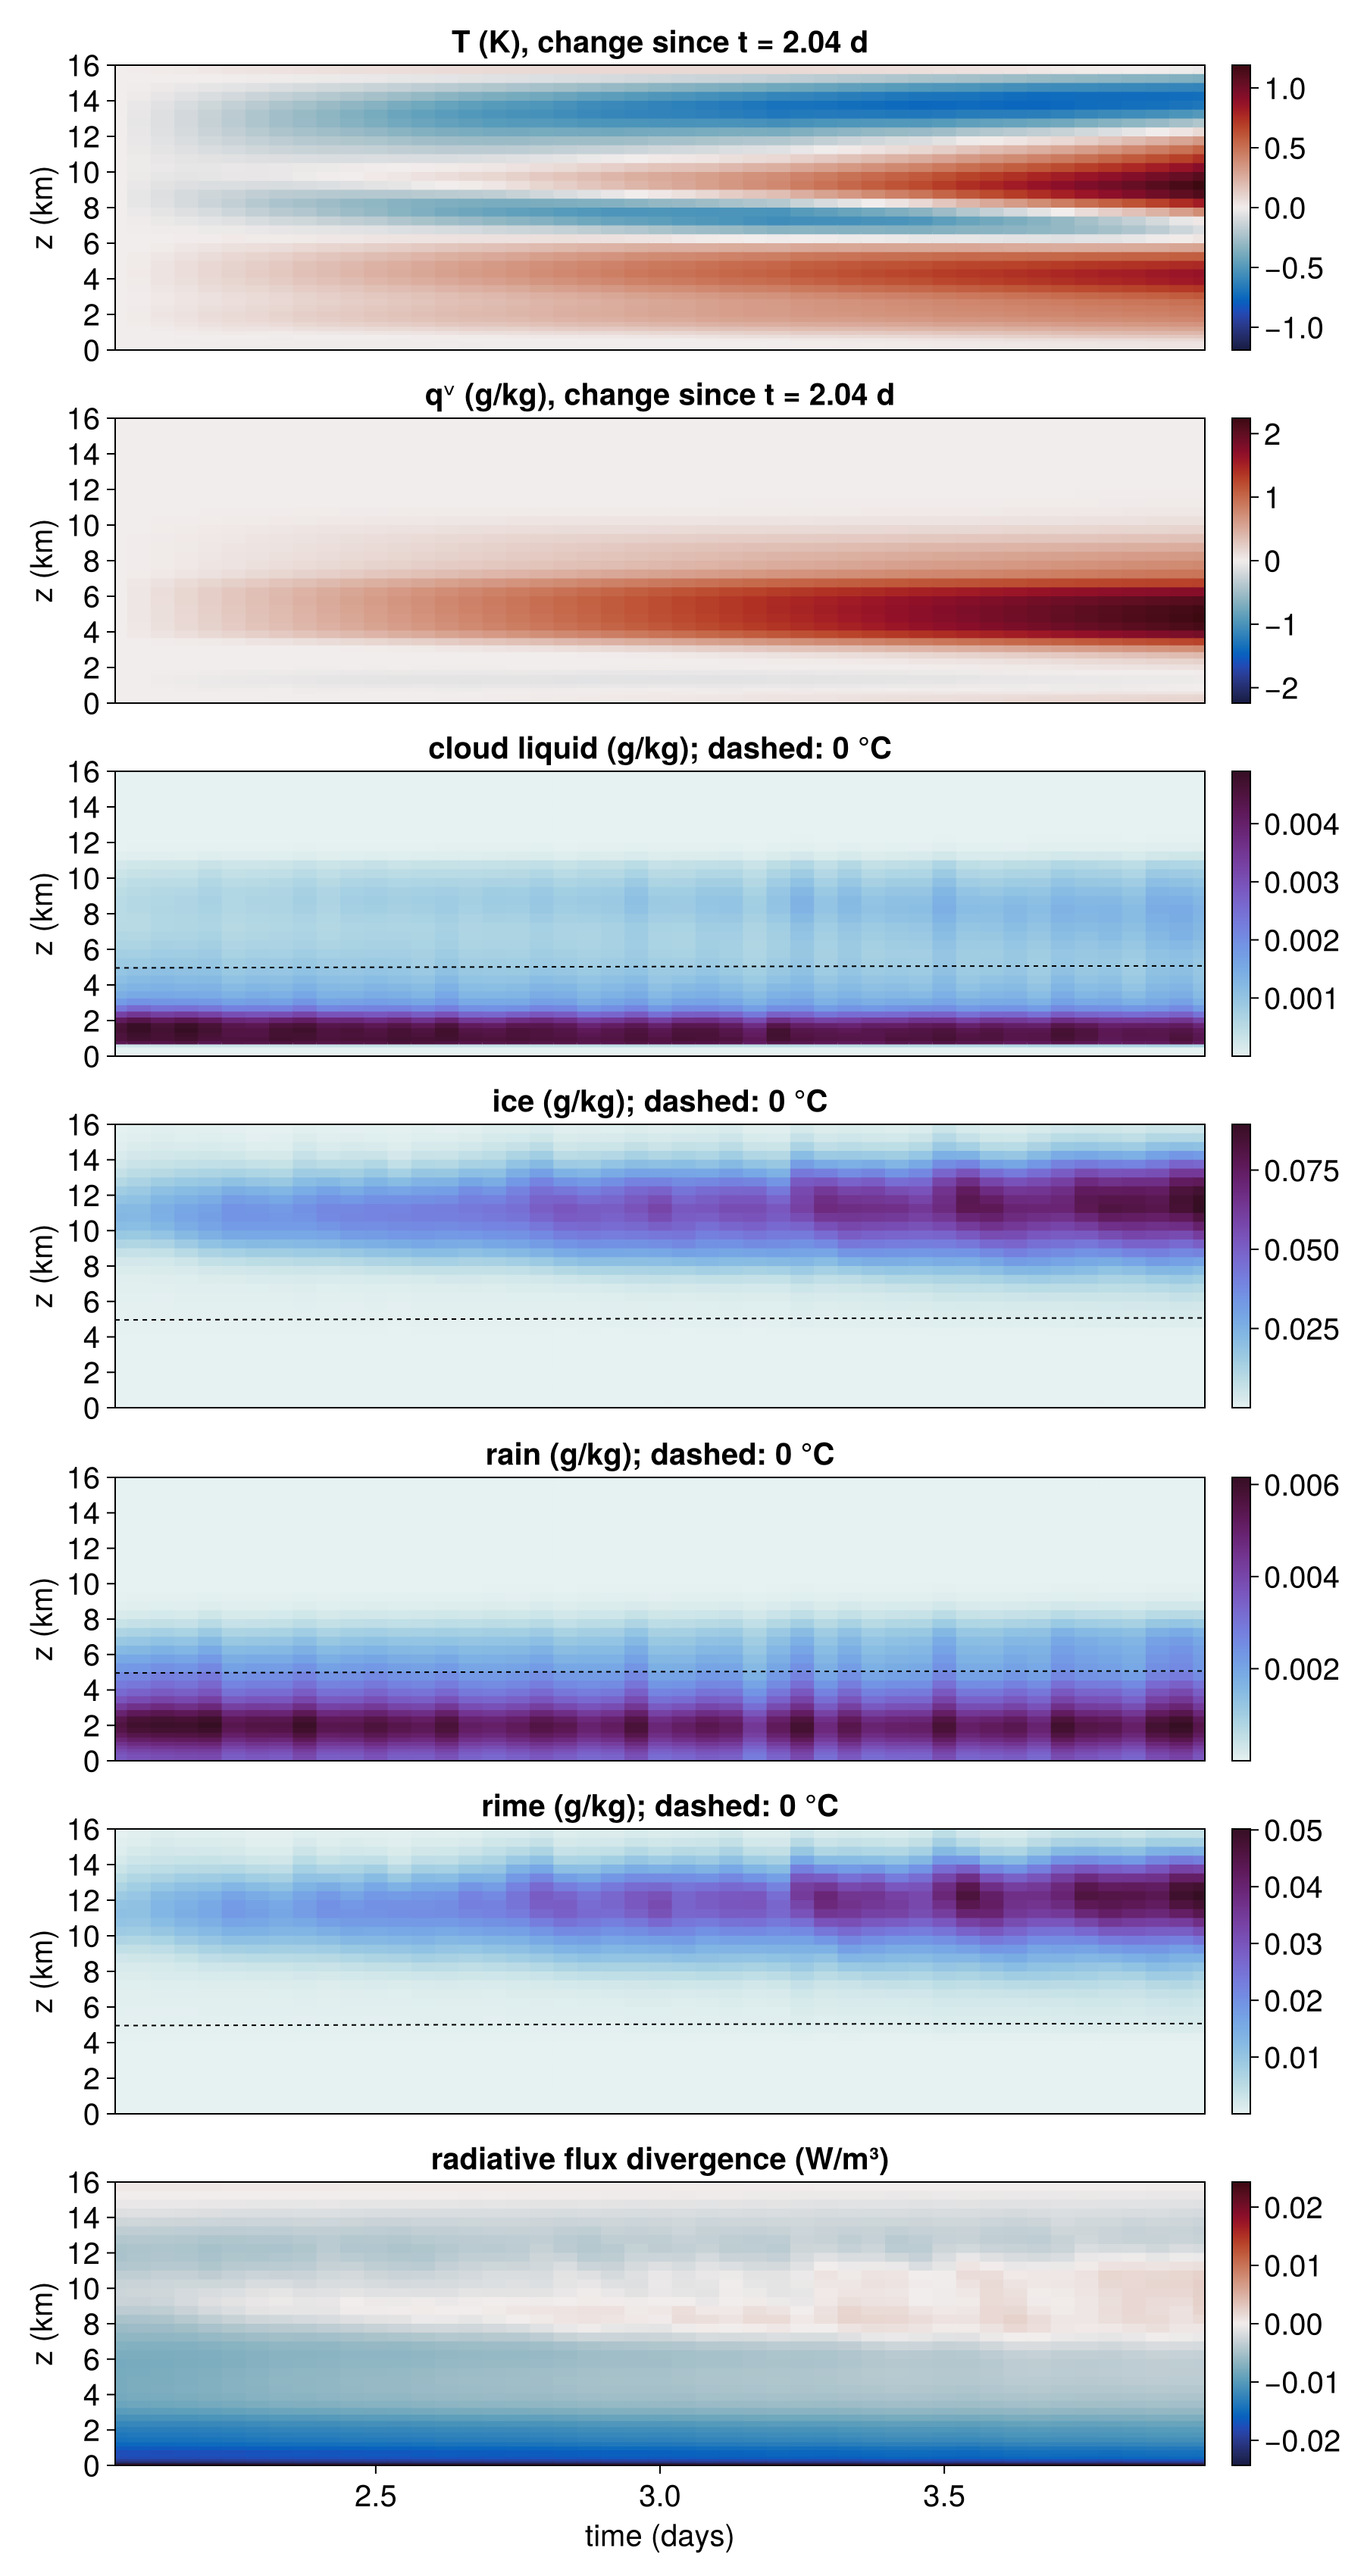

In [19]:
figs_p3["moisten650-440"]

In [20]:
# Numbers behind the P3 first look in notes/STATUS.md: changes from the first to the last output
function p3_summary(r)
    p = read_profiles(p3dir(r))
    zk = p.z ./ 1e3
    Δqv = 1e3 .* (p.qv[:, end] .- p.qv[:, 1])             # g/kg
    ΔT = p.T[:, end] .- p.T[:, 1]                          # K
    top = 10 .<= zk .<= 12
    freezing = zk[findlast(p.T[:, end] .> 273.15)]         # top of the T > 0 °C layer of the mean
    rain_top = zk[findlast(p.qr[:, end] .> 1e-6)]          # highest rain above 0.001 g/kg
    (run = r, days = round(p.t[end]; digits = 2),
     Δqv_max = round(maximum(Δqv); digits = 2), Δqv_z = zk[argmax(Δqv)],
     ΔT_max = round(maximum(ΔT); digits = 2), ΔT_min = round(minimum(ΔT); digits = 2),
     ice_max = round(1e3 * maximum(p.qi[:, end]); digits = 3),
     rime_over_ice = round(mean(p.qf[top, end]) / mean(p.qi[top, end]); digits = 2),   # 10–12 km
     freezing_km = freezing, rain_top_km = rain_top)
end
p3_summary.(p3runs)

4-element Vector{@NamedTuple{run::String, days::Float64, Δqv_max::Float64, Δqv_z::Float64, ΔT_max::Float32, ΔT_min::Float32, ice_max::Float64, rime_over_ice::Float32, freezing_km::Float64, rain_top_km::Float64}}:
 (run = "ctl2", days = 5.71, Δqv_max = 1.09, Δqv_z = 6.25, ΔT_max = 6.6, ΔT_min = -0.88, ice_max = 0.065, rime_over_ice = 0.46, freezing_km = 4.761841796875, rain_top_km = 7.25)
 (run = "moisten1000-850", days = 5.58, Δqv_max = 1.56, Δqv_z = 0.17236842346191406, ΔT_max = 6.87, ΔT_min = -0.82, ice_max = 0.088, rime_over_ice = 0.45, freezing_km = 4.761841796875, rain_top_km = 7.75)
 (run = "moisten850-650", days = 3.88, Δqv_max = 1.38, Δqv_z = 2.007894775390625, ΔT_max = 3.81, ΔT_min = -0.81, ice_max = 0.064, rime_over_ice = 0.47, freezing_km = 4.761841796875, rain_top_km = 7.25)
 (run = "moisten650-440", days = 3.96, Δqv_max = 2.24, Δqv_z = 4.761841796875, ΔT_max = 4.14, ΔT_min = -0.72, ice_max = 0.089, rime_over_ice = 0.48, freezing_km = 4.761841796875, rain_top_km = 7.75)